In [66]:
import cartopy.crs as ccrs
import cartopy.feature as cf
projection = ccrs.Mercator()
crs = ccrs.PlateCarree()

import matplotlib.colors as mcolors

from seasonal_burst.exhaustive_search import exhaustive_search
from seasonal_burst.spatial_search import process_grid
from utils.connected_components import connected_components_bursts


import copy
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import HTML
import matplotlib.animation as animation
import warnings, os

import utils_notebook as ub
#import src.steps as steps
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 16

In [67]:
threshold = 3
grid_data_path="../../Data/SST/medi_1960_2021_processed_focused.nc"
parameter="sst"
n_jobs = 6
minimum_length = 1
maximum_length = 365
absolute_threshold = True
animate = False
export = True
filename_html="example_grid"
print("\033[1m"+"Parameters: "+ "\033[0m")
print(f" - threshold = {threshold}")
print(f" - grid_data_path = \"{grid_data_path}\"")
print(f" - parameter = {parameter}")
print(f" - n_jobs = {n_jobs}")
print(f" - animate = {animate}")
print(f" - export = {export}")
print(f" - filename_html = \"{filename_html}\"")

Parameters: 
 - threshold = 3
 - grid_data_path = "../../Data/SST/medi_1960_2021_processed_focused.nc"
 - parameter = sst
 - n_jobs = 6
 - animate = False
 - export = True
 - filename_html = "example_grid"


In [68]:
ds = xr.open_dataset(grid_data_path)[parameter]
time = ds.time
ts_date = pd.DatetimeIndex(time.values)
len_year = 365
n_year = len(ds.time) // len_year
lat = ds.lat.size
lon = ds.lon.size
lon_min = ds.lon.min().values
lon_max = ds.lon.max().values
lat_min = ds.lat.min().values
lat_max = ds.lat.max().values
values = ds.values.astype(np.float64)
first_year = ts_date[0].year
last_year = ts_date[-1].year
years = range(first_year, last_year+1)

In [69]:
%%time
parameter="sst"
grid = ds
values = grid[0,:,:].values
n, lat, lon = grid.shape
valid_coordinates = [(i,j) for j in range(lon) for i in range(lat) if not np.isnan(values[i, j])]

grid_burst =  process_grid(
    grid,
    valid_coordinates,
    threshold,
    n_year,
    len_year,
    minimum_length,
    maximum_length,
    exhaustive_search,
    n_jobs)

2025-03-14 18:35:41,283 - distributed.worker - ERROR - Failed to communicate with scheduler during heartbeat.
Traceback (most recent call last):
  File "/home/guillaume/miniconda3/envs/seasonal-burst/lib/python3.12/site-packages/distributed/comm/tcp.py", line 226, in read
    frames_nosplit_nbytes_bin = await stream.read_bytes(fmt_size)
                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tornado.iostream.StreamClosedError: Stream is closed

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/home/guillaume/miniconda3/envs/seasonal-burst/lib/python3.12/site-packages/distributed/worker.py", line 1269, in heartbeat
    response = await retry_operation(
               ^^^^^^^^^^^^^^^^^^^^^^
  File "/home/guillaume/miniconda3/envs/seasonal-burst/lib/python3.12/site-packages/distributed/utils_comm.py", line 416, in retry_operation
    return await retry(
           ^^^^^^^^^^^^
  File "/home/guillaume/miniconda3/envs

CPU times: user 42.2 s, sys: 3.97 s, total: 46.1 s
Wall time: 1min 36s


### Number of burst (after merging) per series

In [70]:
values = ds.values.astype(np.float64)

grid_count, grid_count_hot, grid_count_cold, grid_count_days_hot, grid_count_days_cold, coords = ub.compute_grid_counts(grid_burst, lat, lon, values)

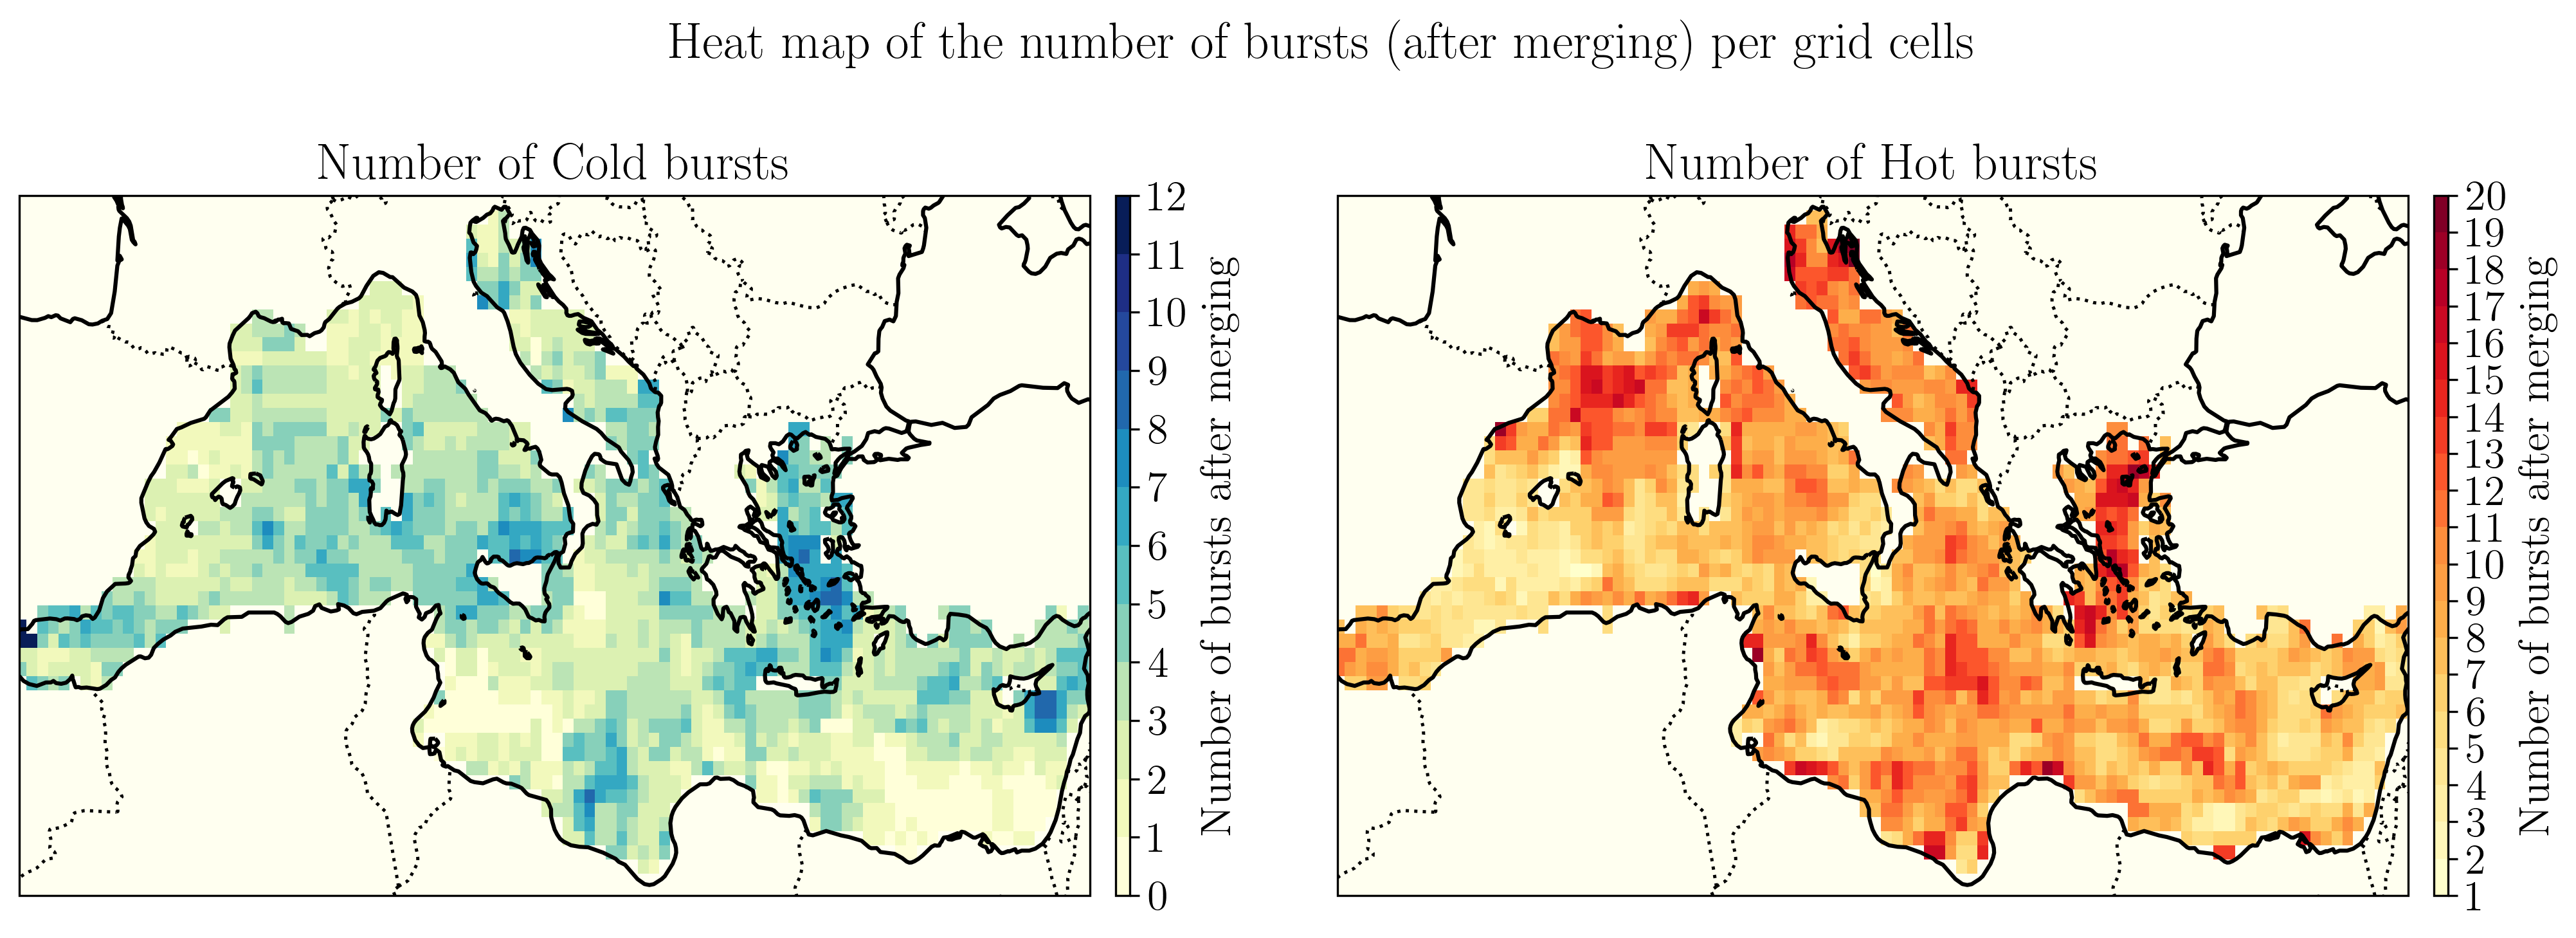

In [71]:
plt.figure(figsize=(14, 5), dpi=300)

# First subplot: Cold bursts
bounds_cold = np.arange(np.nanmin(grid_count_cold), np.nanmax(grid_count_cold)+1, 1)
if len(bounds_cold) > 1:
    ax1 = plt.subplot(1, 2, 1, projection=projection)

    cmap_cold = plt.cm.YlGnBu
    cmap_cold.set_bad(color="ivory")
    norm_cold = mcolors.BoundaryNorm(boundaries=bounds_cold, ncolors=cmap_cold.N) 
    img1 = ax1.imshow(grid_count_cold, cmap=cmap_cold, norm=norm_cold, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax1.coastlines(resolution='50m', linewidth=1.5),ax1.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2),ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar1 = plt.colorbar(img1, ax=ax1, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_cold, ticks=bounds_cold)
    cbar1.set_label('Number of bursts after merging'), ub.hide_ax(ax1), ax1.set_title("Number of Cold bursts ")

# Second subplot: Hot bursts
bounds_hot = np.arange(np.nanmin(grid_count_hot), np.nanmax(grid_count_hot)+1, 1)
if len(bounds_hot) > 1:
    ax2 = plt.subplot(1, 2, 2, projection=projection)
    cmap_hot = plt.cm.YlOrRd
    cmap_hot.set_bad(color="ivory")
    norm_hot = mcolors.BoundaryNorm(boundaries=bounds_hot, ncolors=cmap_hot.N)
    img2 = ax2.imshow(grid_count_hot, cmap=cmap_hot, norm=norm_hot, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax2.coastlines(resolution='50m', linewidth=1.5), ax2.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar2 = plt.colorbar(img2, ax=ax2, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_hot, ticks=bounds_hot)
    cbar2.set_label('Number of bursts after merging'), ub.hide_ax(ax2), ax2.set_title("Number of Hot bursts")

plt.suptitle("Heat map of the number of bursts (after merging) per grid cells"), plt.tight_layout()
plt.show()

In [72]:
plt.figure(figsize=(14, 5))
# First subplot: Cold bursts
if not np.isnan(np.max(grid_count_days_cold)):
    step = max( 1, int(np.nanmax(grid_count_days_cold)//20))
    bounds_cold = np.arange(np.nanmin(grid_count_days_cold), np.nanmax(grid_count_days_cold)+1, step)
    ax1 = plt.subplot(1, 2, 1, projection=projection)
    cmap_cold = plt.cm.YlGnBu
    cmap_cold.set_bad(color="ivory")
    norm_cold = mcolors.BoundaryNorm(boundaries=bounds_cold, ncolors=cmap_cold.N)
    img1 = ax1.imshow(grid_count_days_cold, cmap=cmap_cold, norm=norm_cold, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax1.coastlines(resolution='50m', linewidth=1.5), ax1.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax1.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar1 = plt.colorbar(img1, ax=ax1, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_cold, ticks=bounds_cold)
    cbar1.set_label('Number of bursts days'), ax1.set_title("Number of Cold bursts days")

# Second subplot: Hot bursts
if not np.isnan(np.max(grid_count_days_hot)):
    step = max( 1, int(np.nanmax(grid_count_days_hot)//20))
    bounds_hot = np.arange(np.nanmin(grid_count_days_hot), np.nanmax(grid_count_days_hot)+1, step)
    ax2 = plt.subplot(1, 2, 2, projection=projection)
    cmap_hot = plt.cm.YlOrRd
    cmap_hot.set_bad(color="ivory")
    norm_hot = mcolors.BoundaryNorm(boundaries=bounds_hot, ncolors=cmap_hot.N)
    img2 = ax2.imshow(grid_count_days_hot, cmap=cmap_hot, norm=norm_hot, extent=[lon_min, lon_max, lat_min, lat_max], 
                      transform=ccrs.PlateCarree(), origin='upper', aspect='auto')
    ax2.coastlines(resolution='50m', linewidth=1.5), ax2.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2), ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    cbar2 = plt.colorbar(img2, ax=ax2, orientation='vertical', pad=0.02, aspect=50, boundaries=bounds_hot, ticks=bounds_hot)
    cbar2.set_label('Number of bursts days'), ax2.set_title("Number of Hot bursts days")
plt.suptitle("Heat map of the number of days belonging to bursts per grid cells"), plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

In [73]:
for i in range(lat):
    for j in range(lon):
        if grid_burst[i,j] == None:
            grid_burst[i,j] = []

In [74]:
grid_burst

array([[list([]), list([]), list([]), ..., list([]), list([]), list([])],
       [list([]), list([]), list([]), ..., list([]), list([]), list([])],
       [list([]), list([]), list([]), ..., list([]), list([]), list([])],
       ...,
       [list([]), list([]), list([]), ..., list([]), list([]), list([])],
       [list([]), list([]), list([]), ..., list([]), list([]), list([])],
       [list([]), list([]), list([]), ..., list([]), list([]), list([])]],
      dtype=object)

### Connected Components

In [75]:
hot_grid_burst = np.copy(grid_burst)
for i in range(lat):
    for j in range(lon):
        if grid_burst[i,j] != []:
            l = [b for b in grid_burst[i,j] if b[-1] == -1]
            hot_grid_burst[i,j] = l
connected_components_bursts = connected_components_bursts(hot_grid_burst, 1)
ccs = [cc for cc in connected_components_bursts if len(list(set(cc))) >= 5]
print(f"In total there are {len(connected_components_bursts)} connected component(s). If we keep connected components that have at least 5 components (5 anomalies) we have {len(ccs)} cluster(s)") 

In total there are 421 connected component(s). If we keep connected components that have at least 5 components (5 anomalies) we have 202 cluster(s)


In [76]:
daylies_hot, daylies_cold, series_hot, series_cold = ub.compute_grid_bars(ts_date, grid_burst, coords)

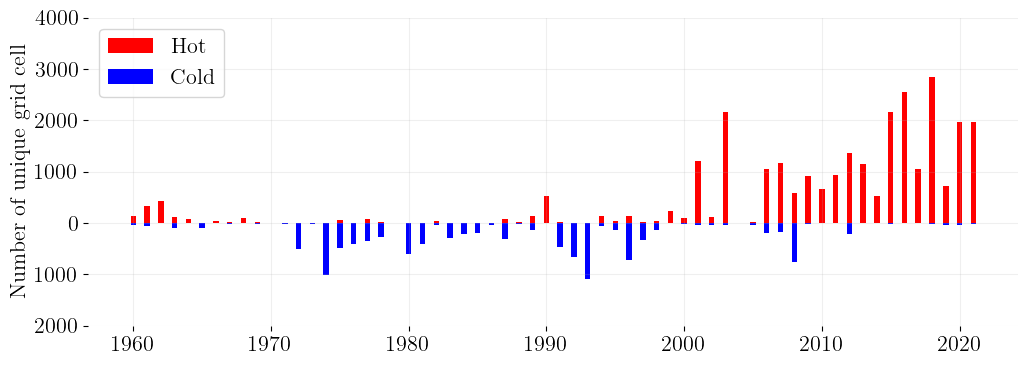

In [77]:
data = {'year': years,
        'hot': series_hot,
        'cold': -series_cold}

plt.figure(figsize=(12, 4)), plt.grid(alpha=0.2)
plt.bar(data['year'], data['hot'], width=0.4, color='red', label='Hot')
plt.bar(data['year'], data['cold'], width=0.4, color='blue', label='Cold')
plt.ylabel('Number of unique grid cell')
ax = plt.gca()
ax.set_yticks(ax.get_yticks().tolist())
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
labels = [int(abs(e)) for e in ax.get_yticks()]
ax.set_yticklabels(labels), plt.legend()
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)
plt.show()

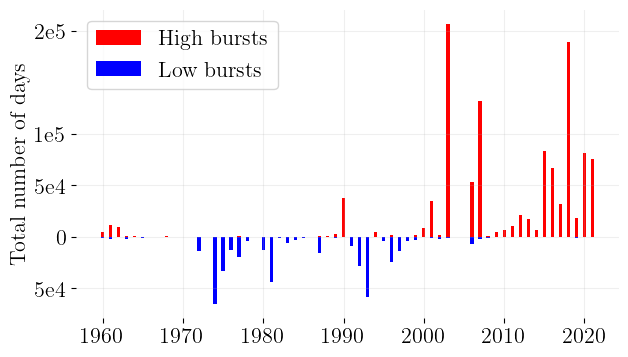

In [78]:
data = {'date': ts_date,
        'hot': daylies_hot,
        'cold': -daylies_cold}

df = pd.DataFrame(data)
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year


yearly_sum = df.groupby('year')[['hot', 'cold']].sum().reset_index()

plt.figure(figsize=(7, 4)), plt.grid(alpha=0.2)
plt.bar(yearly_sum['year'], yearly_sum['hot'], width=0.4, color='red', label='High bursts')
plt.bar(yearly_sum['year'], yearly_sum['cold'], width=0.4, color='blue', label='Low bursts')
plt.ylabel('Total number of days')
ax = plt.gca()
custom_positions = [-50000, 0, 50000, 100000, 200000]  
custom_labels = ['5e4', '0', '5e4', '1e5', '2e5']  
ax.set_yticks(custom_positions)         
ax.set_yticklabels(custom_labels)       

plt.legend()
#ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)
plt.savefig("../figures/yearly_days.pdf", format="pdf", bbox_inches='tight')
plt.show()

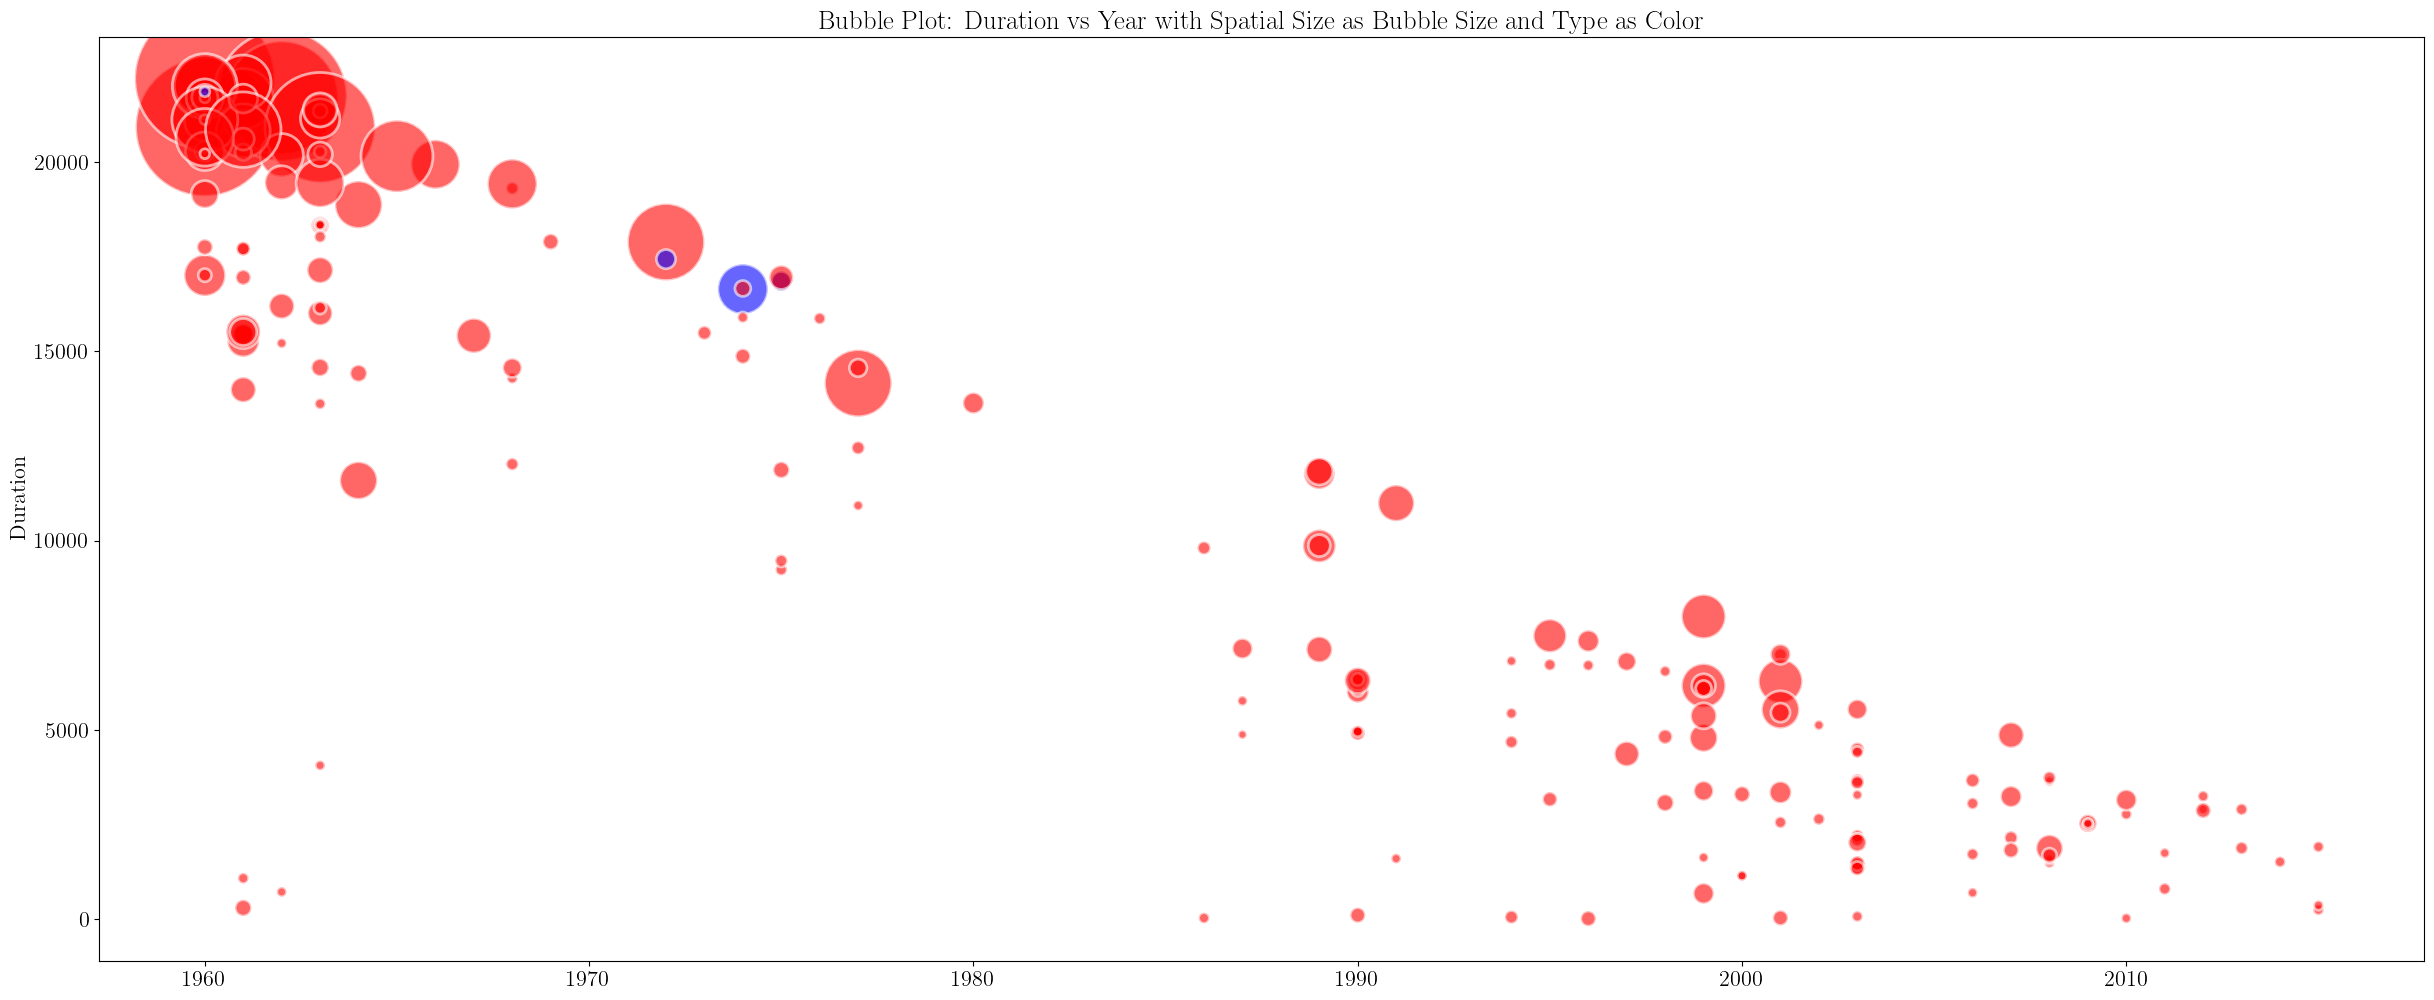

In [79]:
cc_stats, grid_start_5, grid_start_10, grid_start_15, grid_start_20 = ub.compute_cc_stats(grid_burst, ccs, n_year, first_year, lat, lon, coords)
    
df_cc = pd.DataFrame(cc_stats, columns=['Duration', 'Spatial Size', 'Start Year', 'Type'])
# Setting the color based on Type
colors = df_cc['Type'].map({1: 'red', -1: 'blue'})

# Creating the bubble plot
plt.figure(figsize=(30, 12))
plt.scatter(df_cc['Start Year'], df_cc['Duration'], s=df_cc['Spatial Size']*10, c=colors, alpha=0.6, edgecolors="w", linewidth=2)

# Adding labels and title
#plt.xlabel('Year')
plt.ylabel('Duration')
plt.title('Bubble Plot: Duration vs Year with Spatial Size as Bubble Size and Type as Color')
plt.show()

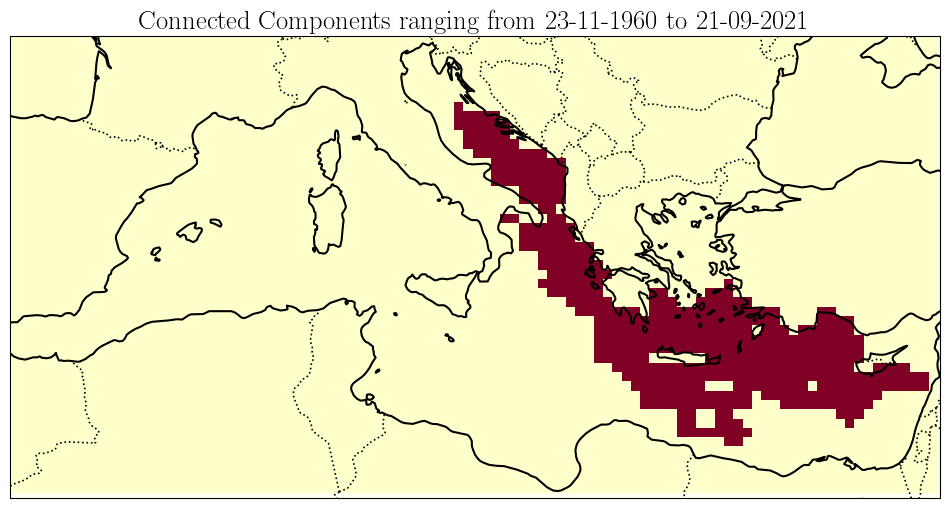

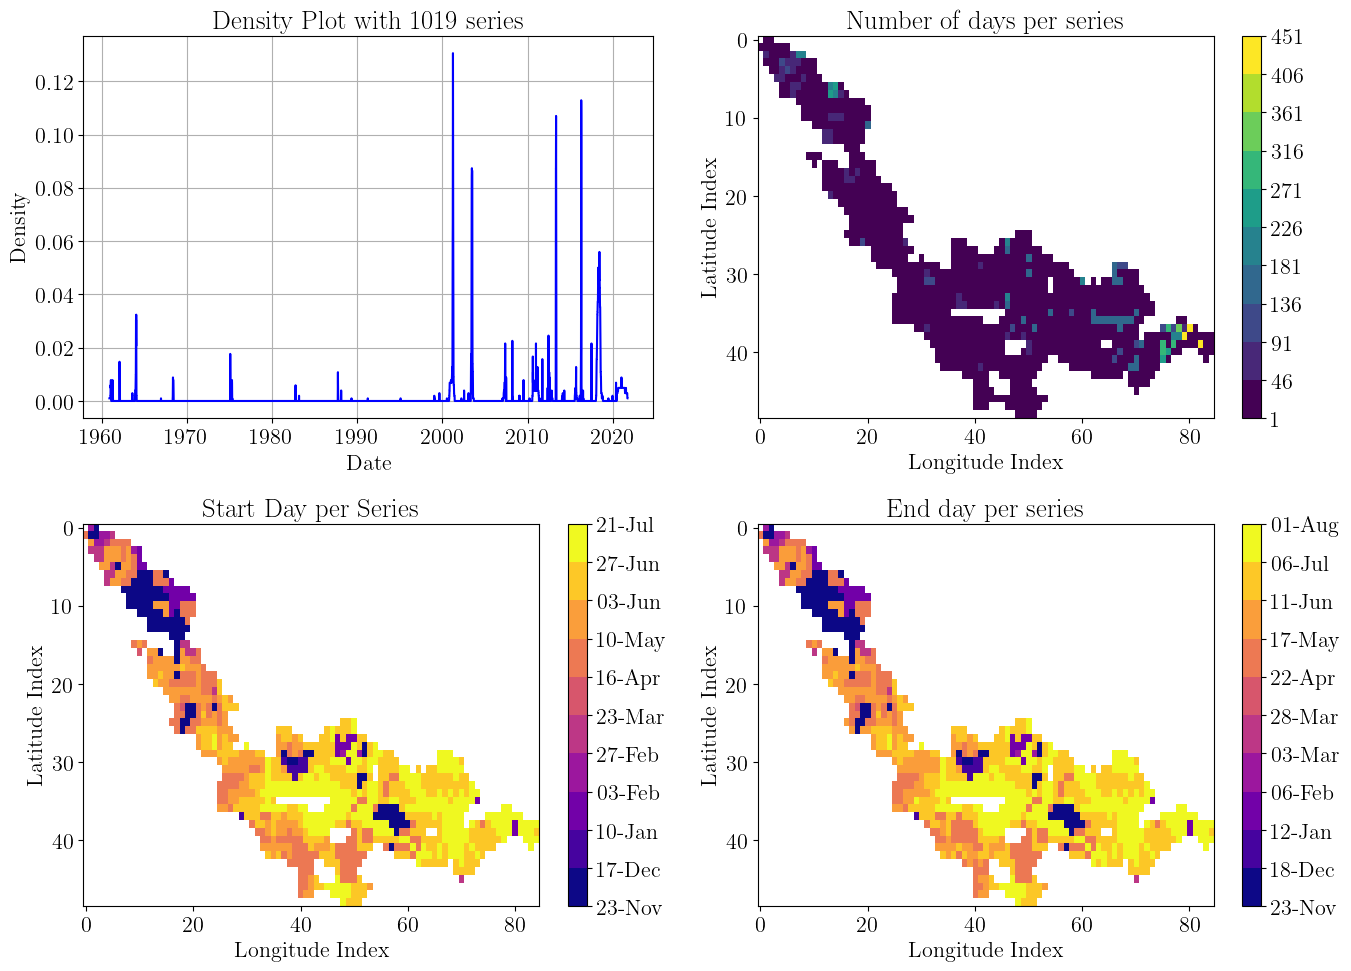

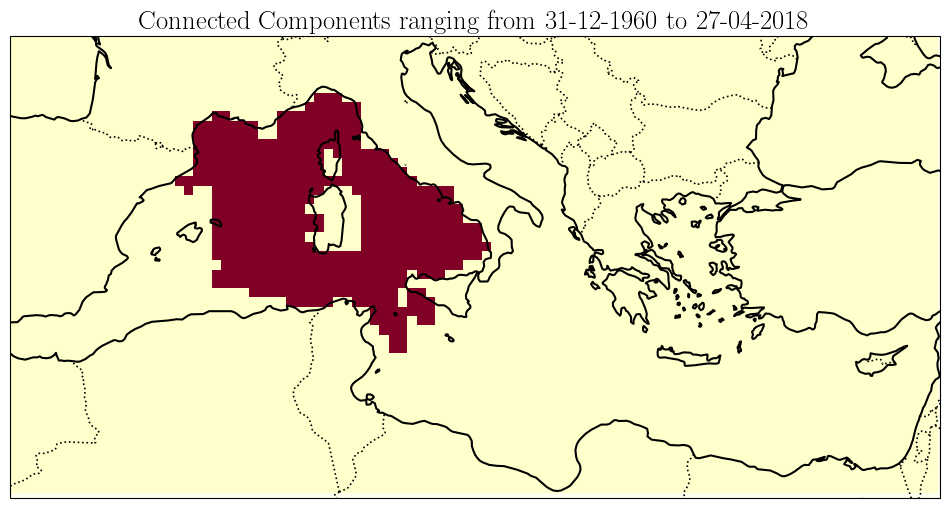

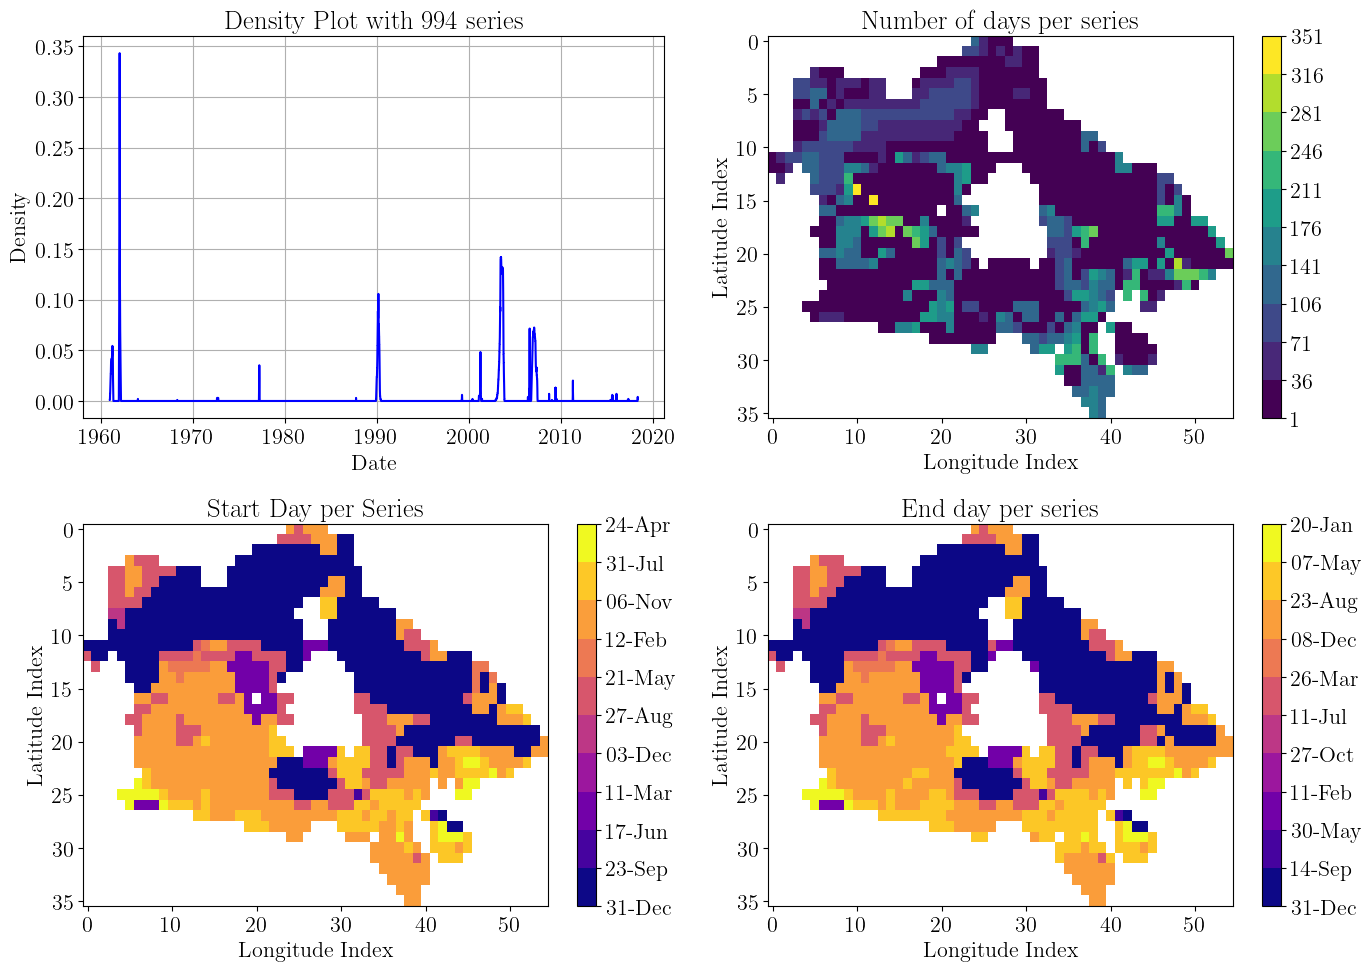

In [80]:
ccs.sort(key=len)
ccs.reverse()
for i, cc in enumerate(ccs[:2]):
    ub.show_connected_component(cc, n_year, ts_date, lat, lon, grid_burst, values, lon_min, lon_max, lat_min, lat_max)

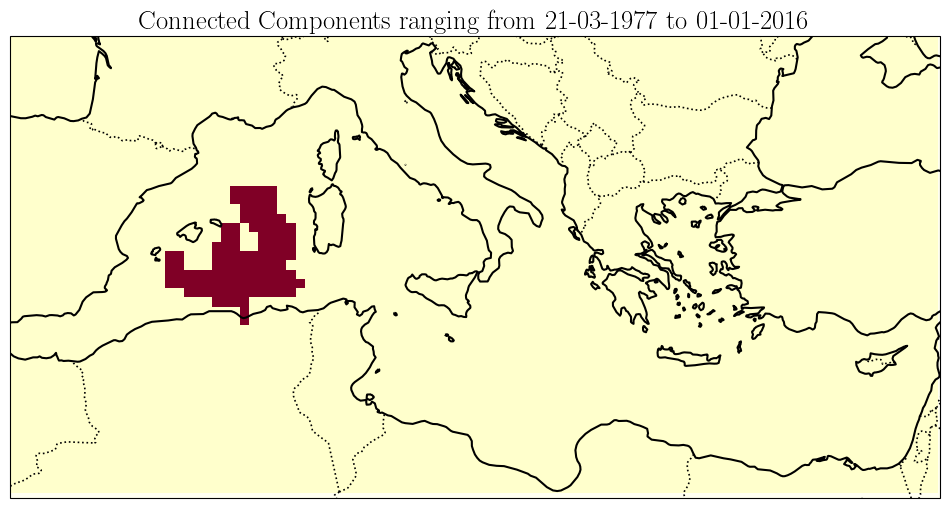

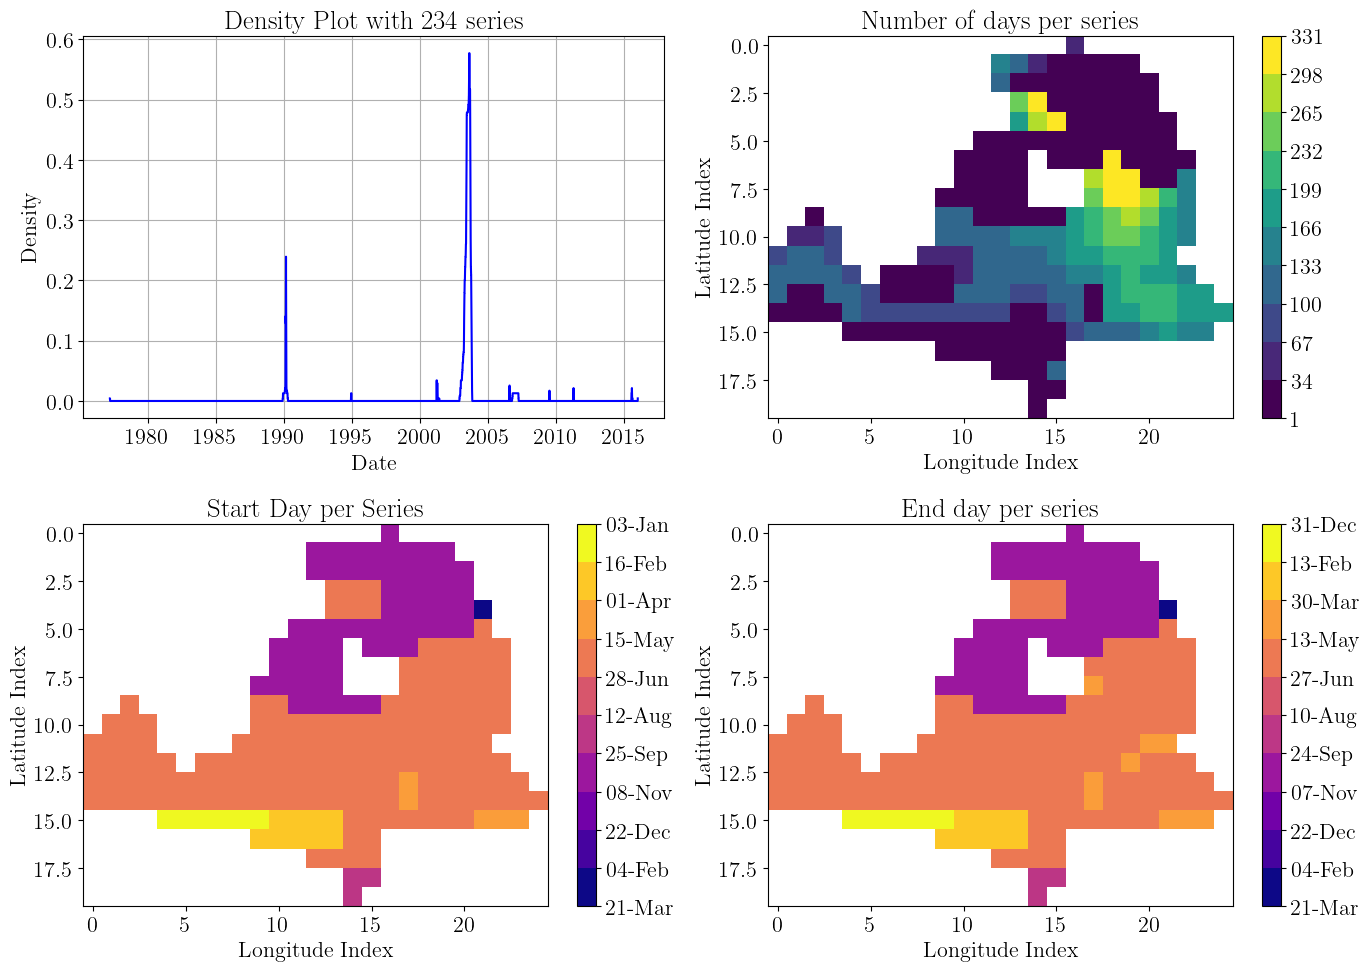

In [81]:
ub.show_connected_component(ccs[9], n_year, ts_date, lat, lon, grid_burst, values, lon_min, lon_max, lat_min, lat_max)

In [ ]:
if True:
    anim = ub.cc_time_travel(ccs[9], ts_date, grid_burst, lat, lon, values)
    HTML(anim.to_jshtml())
    FFwriter = animation.FFMpegWriter(fps=3)
    anim.save('connected_component_time_travel.mp4', writer = FFwriter)


## Time Travel

In [ ]:
if False:
    plt.rcParams['animation.embed_limit'] = 2**128
    start = np.where(ts_date == "01-01-2010")[0][0]
    grid_count = np.zeros((len(ts_date)-start, lat,lon))
    grid_count[:] = np.nan
    for (i,j) in coords:
        grid_count[:, i,j] = 0
        
    for (i,j) in coords:
        for burst in grid_burst[i,j]:
            s,e,z = burst
            if e >= start:
                bend = e - start
                bstart = e - start
                grid_count[bstart:bend+1,i,j] = int(np.sign(z))
    
    grid_weekly_count = np.zeros((1+(len(ts_date)-start)//7, lat,lon))
    grid_weekly_count[:] = np.nan
    for (i,j) in coords:
        grid_weekly_count[:, i,j] = 0
    for i in range(grid_count.shape[1]):
        for j in range(grid_count.shape[2]):
            for w in range(grid_weekly_count.shape[0]):
                grid_weekly_count[w,i,j] = np.sign(np.add.reduce(grid_count[w*7:(w+1)*7,i,j]))
                
    fig, ax = plt.subplots(figsize=(20, 10))
    cmap = ListedColormap(['blue', 'white', 'red'])  # Colors for -1, 0, and 1
    norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)  
    cmap.set_bad(color="darkgrey")
    
    # Initialize the image plot
    img = ax.imshow(grid_weekly_count[0], cmap=cmap, norm=norm)
    plt.close()
    
    # Add text element for displaying the current date
    date_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=20, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))
    formatted_dates = [f'Date: {date.strftime("%Y-%m-%d")}' for date in ts_date[start:start + len(grid_weekly_count) * 7:7]]
    # Update function for animation
    def update(frame):
        img.set_array(grid_weekly_count[frame])
        date_text.set_text(formatted_dates[frame])
        return img, date_text
    
    # Create animation
    anim = FuncAnimation(fig, update, frames=len(grid_weekly_count), interval=200, blit=False, cache_frame_data=False)
    with open("myvideo_weekly.html", "w") as f:
        print(anim.to_jshtml(), file=f)

    FFwriter = animation.FFMpegWriter()
    anim.save('weekly_time_travel.mp4', writer = FFwriter)
    HTML(anim.to_jshtml())

In [ ]:
%%capture output
if export:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        os.system('jupyter nbconvert --no-input --output ' + filename_html + ' --to html ' + "paper_grid.ipynb")

In [ ]:
def grid_length(cc):
    coor = []
    for (i, j, burst_id) in cc:
        if not (i,j) in coor:
            coor.append((i,j))
    return len(coor)

In [ ]:
len(ccs[5])


In [ ]:
def show_connected_components(cc_list, n_year, ts_date, lat, lon, grid_burst, lon_min, lon_max, lat_min, lat_max):
    filtered_cc_list = [cc for cc in cc_list if grid_length(cc) >= 100 and grid_length(cc) <= 1000]  # Only keep components with >= 10 grid cells
   
    grid = np.zeros((lat, lon, len(filtered_cc_list)))


    for idx, cc in enumerate(filtered_cc_list, start=1):
        for (i, j, burst_id) in cc:
            grid[i, j, idx-1] = 1

    plt.figure(figsize=(12, 6))
    projection = ccrs.Mercator()
    crs = ccrs.PlateCarree()
    ax = plt.axes(projection=projection)

    cmap = plt.cm.tab20  # Use a qualitative colormap for distinct components

    for idx in range(1, len(filtered_cc_list) + 1):
        component_mask = (grid[:,:,idx-1] == 1)
        if np.any(component_mask):
            ax.contourf(np.flipud(component_mask), levels=[0.5, 1.5], colors="red", alpha=0.6,
                        extent=[lon_min, lon_max, lat_min, lat_max], transform=ccrs.PlateCarree())

    ax.coastlines(resolution='50m', linewidth=1.5)
    ax.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2)
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)

    plt.title(f"Connected Components Heatmap (>=10 grid cells)")
    plt.show()


In [ ]:
show_connected_components(ccs, n_year, ts_date, lat, lon, grid_burst, lon_min, lon_max, lat_min, lat_max)